# Style classifier: how much of "sounds like me" did the adapter learn?
The loss tells me how well the adapter predicts my tokens, not whether it writes like me. Decision 18: the loss is limited by data and there isn't much more, so the next question is a different one: does what it generates sound like me?

Method (decision 18):

1. **Train a classifier on real messages only:** my replies (label 1) vs my friends' (label 0), from the same train sessions as the adapter (`data/style/`, `build_style.py`). Valid sessions for model selection.
2. **Freeze it.** It never sees a generated message in training.
3. **Generate** one reply for each of the 1,133 test contexts (20 turns, decision 17) with the adapter (`run1_5ep`, step 2500) and with the base model, same sampling for both.
4. **Score** with the frozen classifier: my real test replies (ceiling), the adapter's (what I measure), the base model's (floor), and my friends' test replies (false positives). Metric: % classified as me and mean P(me), with a 95% bootstrap CI by session. Position of the adapter = (adapter − base) / (real − base).

Three classifiers, so I know what each one picks up:
- **Length only** (logistic regression on length): if this already separates well, a "sounds like me" result may just be "has my length".
- **TF-IDF of character n-grams + logistic regression**: the classic stylometry baseline (spelling, punctuation, emojis, laughs).
- **Transformer** (`mdeberta-v3-base`, multilingual; BETO as an alternative), fine-tuned on MPS.

_My prediction:_ The classifier gives an upper bound with my real replies and a lower bound with the base model. The adapter should land somewhere in between. It can't sound more like me than I do: if it does, the classifier is badly trained.

_Note:_ there is one other way the adapter could score above my real replies without the classifier being wrong: caricature. If the adapter overuses my most typical tics (the same laugh, the same short "vale"), every reply looks very "me" to the classifier, more than my real replies, which are more varied. If that happens, look at the diversity of the generations before blaming the classifier.

In [3]:
import json, math, os, random, time
import numpy as np
import matplotlib.pyplot as plt

SEED = 0
STYLE = "../data/style"                       # build_style.py: {"text", "label", "session"}; 1 = me, 0 = friends
CONTEXTOS = "../data/dataset/session_ctx20/test.jsonl"  # 20-turn test contexts, same targets as session/test
GENERACIONES = "../data/style"                # generated text is private: kept under data/, never in git
MODELOS = "../models"                         # fine-tuned classifiers (gitignored)

TRANSFORMER = "microsoft/mdeberta-v3-base"    # alternative: "dccuchile/bert-base-spanish-wwm-cased" (BETO)
MAX_LEN = 64       # tokens per message for the transformer; my replies are short

## Data

In [4]:
def leer(ruta):
    with open(ruta) as f:
        return [json.loads(l) for l in f if l.strip()]

datos = {name: leer(f"{STYLE}/{name}.jsonl") for name in ["train", "valid", "test"]}
for name, filas in datos.items():
    yo = sum(r["label"] for r in filas)
    print(f"{name:>5}: mine {yo:>5} | friends {len(filas) - yo:>5} | sessions {len({r['session'] for r in filas})}")

textos = {k: [r["text"] for r in v] for k, v in datos.items()}
etiquetas = {k: np.array([r["label"] for r in v]) for k, v in datos.items()}

# The test set: my replies come first, in the same order as the generation contexts.
mios_test = [r for r in datos["test"] if r["label"] == 1]
amigos_test = [r for r in datos["test"] if r["label"] == 0]
contextos = leer(CONTEXTOS)
assert [r["text"] for r in mios_test] == [c["messages"][-1]["content"] for c in contextos], "contexts and my test replies are not aligned"
sesion_test = [r["session"] for r in mios_test]          # session of each generation context
sesion_amigos = [r["session"] for r in amigos_test]
print(f"{len(contextos)} generation contexts, aligned with my test replies")

train: mine  5404 | friends  5310 | sessions 499
valid: mine  1012 | friends  1002 | sessions 61
 test: mine  1133 | friends  1110 | sessions 67
1133 generation contexts, aligned with my test replies


## Metrics on real messages
Accuracy and F1 at a 0.5 threshold, and AUC. All on `valid` for model selection and on `test` once.

In [5]:
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

def metricas(y, p):
    return {"acc": accuracy_score(y, p >= 0.5), "f1": f1_score(y, p >= 0.5), "auc": roc_auc_score(y, p)}

def imprimir(nombre, y_valid, p_valid, y_test, p_test):
    v, t = metricas(y_valid, p_valid), metricas(y_test, p_test)
    print(f"{nombre:<12} valid acc {v['acc']:.3f} f1 {v['f1']:.3f} auc {v['auc']:.3f} | "
          f"test acc {t['acc']:.3f} f1 {t['f1']:.3f} auc {t['auc']:.3f}")

clasificadores = {}  # name -> function(list of texts) -> P(me)

### Baseline A: length only

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

def longitud(textos_):
    # log of characters and of words: replies go from "ok" to paragraphs
    return np.array([[math.log1p(len(t)), math.log1p(len(t.split()))] for t in textos_])

solo_longitud = make_pipeline(FunctionTransformer(longitud), StandardScaler(), LogisticRegression())
solo_longitud.fit(textos["train"], etiquetas["train"])
clasificadores["length"] = lambda ts: solo_longitud.predict_proba(ts)[:, 1]
imprimir("length", etiquetas["valid"], clasificadores["length"](textos["valid"]),
         etiquetas["test"], clasificadores["length"](textos["test"]))

length       valid acc 0.536 f1 0.508 auc 0.561 | test acc 0.543 f1 0.511 auc 0.551


### Baseline B: TF-IDF of character n-grams
`char_wb` 2-5 grams, without lowercasing (capitals are style too). C chosen on valid AUC.

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer

mejor_tfidf, mejor_auc = None, -1
for C in [0.3, 1, 3, 10]:
    modelo = make_pipeline(
        TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), lowercase=False, min_df=2, sublinear_tf=True),
        LogisticRegression(C=C, max_iter=3000))
    modelo.fit(textos["train"], etiquetas["train"])
    auc = roc_auc_score(etiquetas["valid"], modelo.predict_proba(textos["valid"])[:, 1])
    print(f"C {C:>4}: valid auc {auc:.3f}")
    if auc > mejor_auc:
        mejor_tfidf, mejor_auc = modelo, auc

clasificadores["tfidf"] = lambda ts: mejor_tfidf.predict_proba(ts)[:, 1]
imprimir("tfidf", etiquetas["valid"], clasificadores["tfidf"](textos["valid"]),
         etiquetas["test"], clasificadores["tfidf"](textos["test"]))

C  0.3: valid auc 0.824
C    1: valid auc 0.831
C    3: valid auc 0.828
C   10: valid auc 0.820
tfidf        valid acc 0.739 f1 0.748 auc 0.831 | test acc 0.752 f1 0.762 auc 0.840


### Transformer
Fine-tuning on MPS: AdamW lr 2e-5, batch 32, linear schedule with 10% warmup, up to 3 epochs, keeping the epoch with the best valid AUC (early stopping, patience 1). The best model is saved under `models/`, so running this cell again just loads it. ~1 s per step, ~6 min per epoch.

In [8]:
import torch
# Cap MPS memory at half of what macOS recommends (~10 GB here): past the cap it raises an
# error instead of filling the RAM and swapping (it reached 26 GB without it).
torch.mps.set_per_process_memory_fraction(0.5)
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

DISPOSITIVO = "mps" if torch.backends.mps.is_available() else "cpu"
RUTA_MODELO = f"{MODELOS}/style_{TRANSFORMER.split('/')[-1]}"

def probabilidades(modelo, tok, textos_, lote=64):
    # P(me) for a list of texts, in batches, no gradients.
    modelo.eval()
    salida = []
    with torch.no_grad():
        for i in range(0, len(textos_), lote):
            # padding to a fixed length: every batch has the same shape, so MPS reuses its buffers
            x = tok(textos_[i:i + lote], truncation=True, max_length=MAX_LEN, padding="max_length", return_tensors="pt").to(DISPOSITIVO)
            salida.append(torch.softmax(modelo(**x).logits.float(), dim=-1)[:, 1].cpu().numpy())
    torch.mps.empty_cache()
    return np.concatenate(salida)

def entrenar_transformer(epocas=3, lote=32, lr=2e-5, paciencia=1):
    tok = AutoTokenizer.from_pretrained(TRANSFORMER)
    # dtype=float32: the checkpoint is stored in fp16 and transformers loads it as is;
    # in fp16 the loss goes to NaN after the first optimizer step on MPS.
    modelo = AutoModelForSequenceClassification.from_pretrained(TRANSFORMER, num_labels=2, dtype=torch.float32).to(DISPOSITIVO)
    torch.manual_seed(SEED)
    optim = torch.optim.AdamW(modelo.parameters(), lr=lr, weight_decay=0.01)
    pasos = epocas * math.ceil(len(textos["train"]) / lote)
    plan = get_linear_schedule_with_warmup(optim, int(0.1 * pasos), pasos)
    orden = np.random.default_rng(SEED)
    mejor, sin_mejora = -1, 0
    for epoca in range(epocas):
        modelo.train()
        indices = orden.permutation(len(textos["train"]))
        inicio = time.time()
        for k in range(0, len(indices), lote):
            idx = indices[k:k + lote]
            x = tok([textos["train"][i] for i in idx], truncation=True, max_length=MAX_LEN, padding="max_length", return_tensors="pt").to(DISPOSITIVO)
            y = torch.tensor(etiquetas["train"][idx], device=DISPOSITIVO)
            perdida = modelo(**x, labels=y).loss
            perdida.backward()
            optim.step(); plan.step(); optim.zero_grad()
            if (k // lote) % 50 == 0:
                torch.mps.empty_cache()
        auc = roc_auc_score(etiquetas["valid"], probabilidades(modelo, tok, textos["valid"]))
        print(f"epoch {epoca + 1}: valid auc {auc:.3f} ({(time.time() - inicio) / 60:.1f} min)")
        if auc > mejor:
            mejor, sin_mejora = auc, 0
            modelo.save_pretrained(RUTA_MODELO); tok.save_pretrained(RUTA_MODELO)
        else:
            sin_mejora += 1
            if sin_mejora > paciencia - 1:
                break

if not os.path.exists(RUTA_MODELO):
    entrenar_transformer()
    torch.mps.empty_cache()  # free the optimizer state before loading the best model
tok_t = AutoTokenizer.from_pretrained(RUTA_MODELO)
modelo_t = AutoModelForSequenceClassification.from_pretrained(RUTA_MODELO, dtype=torch.float32).to(DISPOSITIVO)
clasificadores["transformer"] = lambda ts: probabilidades(modelo_t, tok_t, ts)
imprimir("transformer", etiquetas["valid"], clasificadores["transformer"](textos["valid"]),
         etiquetas["test"], clasificadores["transformer"](textos["test"]))

.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

transformer  valid acc 0.767 f1 0.781 auc 0.847 | test acc 0.770 f1 0.780 auc 0.867


## Generation
One reply per test context (20 turns of history), with the base model and with `run1_5ep` at step 2500. Same sampling for both: temperature 0.7, top-p 0.9, at most 256 tokens (the same cap as my real replies, so length isn't truncated for one side only), stops at `<|im_end|>`. The seed is set per context (`SEED + k`), so a stopped run resumes with the same results. Saved after every reply. Only counts and lengths are printed.

In [9]:
import mlx.core as mx
from mlx_lm import load, generate
from mlx_lm.sample_utils import make_sampler

MODELO = "mlx-community/Qwen2.5-0.5B-Instruct-4bit"
ADAPTADOR, PASO = "../adapters/run1_5ep", 2500  # best checkpoint (decisions 15-17)

def generar(nombre, model, tokenizer, temp=0.7, top_p=0.9):
    ruta = f"{GENERACIONES}/generations_{nombre}.jsonl"
    hechas = leer(ruta) if os.path.exists(ruta) else []
    sampler = make_sampler(temp=temp, top_p=top_p)
    inicio = time.time()
    with open(ruta, "a") as f:
        for k in range(len(hechas), len(contextos)):
            mx.random.seed(SEED + k)
            prompt = tokenizer.apply_chat_template(contextos[k]["messages"][:-1], add_generation_prompt=True)
            texto = generate(model, tokenizer, prompt=prompt, max_tokens=256, sampler=sampler)
            f.write(json.dumps({"k": k, "text": texto}, ensure_ascii=False) + "\n"); f.flush()
            hechas.append({"k": k, "text": texto})
            if (k + 1) % 100 == 0:
                print(f"{nombre}: {k + 1}/{len(contextos)} ({(time.time() - inicio) / 60:.1f} min)")
    textos_ = [h["text"] for h in hechas]
    print(f"{nombre}: {len(textos_)} replies | mean chars {np.mean([len(t) for t in textos_]):.0f} | empty {sum(not t.strip() for t in textos_)}")
    return textos_

In [10]:
model, tokenizer = load(MODELO, adapter_path=ADAPTADOR)
model.load_weights(f"{ADAPTADOR}/{PASO:07d}_adapters.safetensors", strict=False)
gen_adaptador = generar("adapter", model, tokenizer)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

adapter: 1133 replies | mean chars 44 | empty 0


In [11]:
model, tokenizer = load(MODELO)  # base, no adapter
gen_base = generar("base", model, tokenizer)
print(f"mine (real): mean chars {np.mean([len(r['text']) for r in mios_test]):.0f}")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

base: 1133 replies | mean chars 210 | empty 0
mine (real): mean chars 48


## Scoring
Each frozen classifier on four sets: my real test replies (ceiling), the adapter's, the base model's, and my friends' test replies (how often a friend passes as me). Share classified as me (P ≥ 0.5) and mean P(me). The bootstrap resamples test sessions (1000, seed 0) jointly for all sets, since real, adapter and base answer the same contexts; position = (adapter − base) / (real − base): 0 = base, 1 = me.

In [12]:
conjuntos = {"base": gen_base, "adapter": gen_adaptador, "real (me)": [r["text"] for r in mios_test],
             "friends": [r["text"] for r in amigos_test]}
sesiones_de = {"base": sesion_test, "adapter": sesion_test, "real (me)": sesion_test, "friends": sesion_amigos}

def por_sesion(valores, etiquetas_):
    sumas = {}
    for v, s in zip(valores, etiquetas_):
        sumas.setdefault(s, []).append(v)
    return {s: (sum(v), len(v)) for s, v in sumas.items()}

def media(sumas, elegidas):
    tot, n = 0.0, 0
    for s in elegidas:
        a, b = sumas.get(s, (0.0, 0))
        tot += a; n += b
    return tot / n

puntuaciones = {}
for nombre_c, clasificar in clasificadores.items():
    p = {k: clasificar(v) for k, v in conjuntos.items()}
    sumas = {k: por_sesion((p[k] >= 0.5).astype(float), sesiones_de[k]) for k in conjuntos}
    sesiones = sorted(set(sesion_test) | set(sesion_amigos))
    random.seed(SEED)
    remuestras = {k: [] for k in conjuntos} | {"position": []}
    for _ in range(1000):
        elegidas = random.choices(sesiones, k=len(sesiones))
        r = {k: media(sumas[k], elegidas) for k in conjuntos}
        for k in conjuntos:
            remuestras[k].append(r[k])
        if r["real (me)"] != r["base"]:
            remuestras["position"].append((r["adapter"] - r["base"]) / (r["real (me)"] - r["base"]))
    fila = {}
    for k in conjuntos:
        fila[k] = {"share": float(np.mean(p[k] >= 0.5)), "mean_p": float(np.mean(p[k])),
                   "ci": [float(x) for x in np.percentile(remuestras[k], [2.5, 97.5])]}
    posicion = (fila["adapter"]["share"] - fila["base"]["share"]) / (fila["real (me)"]["share"] - fila["base"]["share"])
    fila["position"] = {"value": posicion, "ci": [float(x) for x in np.percentile(remuestras["position"], [2.5, 97.5])]}
    puntuaciones[nombre_c] = fila

    print(f"\n{nombre_c}")
    for k in conjuntos:
        f_ = fila[k]
        print(f"  {k:<10} classified as me {f_['share']:>6.1%} [{f_['ci'][0]:.1%}, {f_['ci'][1]:.1%}] | mean P(me) {f_['mean_p']:.3f}")
    print(f"  position of the adapter: {posicion:.2f} [{fila['position']['ci'][0]:.2f}, {fila['position']['ci'][1]:.2f}]")

with open("results/style_classifier.json", "w") as f:
    json.dump({"source": "experiments/StyleClassifier.ipynb", "transformer": TRANSFORMER,
               "adapter": f"{ADAPTADOR.removeprefix('../')}@{PASO}", "sampling": {"temp": 0.7, "top_p": 0.9, "max_tokens": 256},
               "scores": puntuaciones}, f, indent=2)


length
  base       classified as me  12.8% [9.7%, 15.2%] | mean P(me) 0.464
  adapter    classified as me  62.0% [58.4%, 65.6%] | mean P(me) 0.518
  real (me)  classified as me  47.4% [43.1%, 51.4%] | mean P(me) 0.506
  friends    classified as me  38.7% [32.8%, 44.8%] | mean P(me) 0.501
  position of the adapter: 1.42 [1.28, 1.57]

tfidf
  base       classified as me  57.2% [53.0%, 61.9%] | mean P(me) 0.533
  adapter    classified as me  87.5% [85.4%, 89.2%] | mean P(me) 0.697
  real (me)  classified as me  78.8% [74.5%, 83.3%] | mean P(me) 0.642
  friends    classified as me  28.6% [20.8%, 37.4%] | mean P(me) 0.373
  position of the adapter: 1.40 [1.12, 1.82]

transformer
  base       classified as me  66.9% [61.9%, 71.7%] | mean P(me) 0.643
  adapter    classified as me  89.7% [88.3%, 91.0%] | mean P(me) 0.811
  real (me)  classified as me  80.5% [77.9%, 83.5%] | mean P(me) 0.743
  friends    classified as me  26.5% [19.1%, 34.2%] | mean P(me) 0.265
  position of the adapter: 1.68

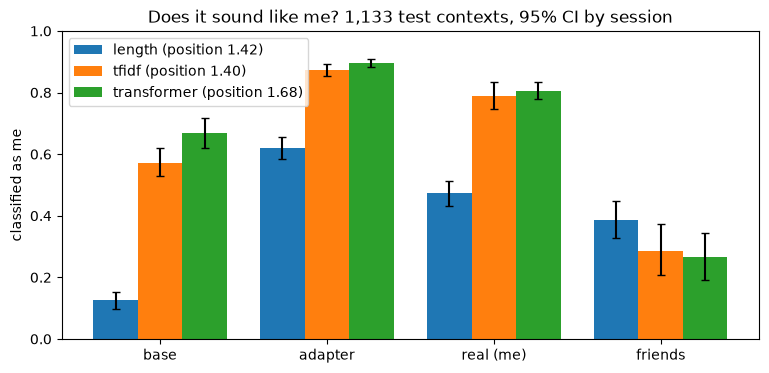

In [13]:
orden_barras = ["base", "adapter", "real (me)", "friends"]
fig, eje = plt.subplots(figsize=(9, 4))
ancho = 0.8 / len(puntuaciones)
for j, (nombre_c, fila) in enumerate(puntuaciones.items()):
    xs = np.arange(len(orden_barras)) + j * ancho
    ys = [fila[k]["share"] for k in orden_barras]
    err = [[y - fila[k]["ci"][0] for y, k in zip(ys, orden_barras)], [fila[k]["ci"][1] - y for y, k in zip(ys, orden_barras)]]
    eje.bar(xs, ys, ancho, yerr=err, capsize=3, label=f"{nombre_c} (position {fila['position']['value']:.2f})")
eje.set_xticks(np.arange(len(orden_barras)) + ancho * (len(puntuaciones) - 1) / 2, orden_barras)
eje.set_ylabel("classified as me"); eje.set_ylim(0, 1)
eje.set_title("Does it sound like me? 1,133 test contexts, 95% CI by session")
eje.legend()
plt.show()

### First reading
Length alone can't tell me from my friends: mean P(me) is ~0.5 for every set (the base model a bit lower, 0.46). That's expected: my WhatsApp messages and my friends' have similar lengths. TF-IDF separates my messages from my friends' clearly. The transformer is only ~2 points better at classifying, but it is noticeably more confident (higher mean P(me)).

What I didn't expect: both classifiers put the adapter **above** my own messages. TF-IDF classifies 78.8% of my real replies as mine and 87.5% of the adapter's (position 1.40); the transformer, 80.5% and 89.7% (position 1.68). The adapter is "more me than me".

I don't know why yet, and I need to know before publishing anything. So I check it below: length, variety, how many of the adapter's replies are copied straight from train (my guess: very repeated short ones, a laugh, an "ok"), the score without those copies, and generations with less restrictive sampling.

## Why does the adapter score above me?
Five checks on the same four sets (base, adapter, real, friends). Only counts and percentages are printed, never text.

### (a) Length
Characters per reply in each set, and the share classified as me by length bin, for TF-IDF and the transformer.

In [14]:
BINS = [0, 10, 20, 40, 80, 160, 10**9]
ETIQ_BINS = ["<10", "10-19", "20-39", "40-79", "80-159", "160+"]

def bin_de(t):
    return next(i for i in range(len(BINS) - 1) if BINS[i] <= len(t) < BINS[i + 1])

print(f"{'set':<10} {'mean':>5} {'p25':>4} {'median':>6} {'p75':>4} | " + " ".join(f"{b:>7}" for b in ETIQ_BINS))
for k, ts in conjuntos.items():
    lens = np.array([len(t) for t in ts])
    reparto = np.bincount([bin_de(t) for t in ts], minlength=len(ETIQ_BINS)) / len(ts)
    print(f"{k:<10} {lens.mean():>5.0f} {np.percentile(lens, 25):>4.0f} {np.median(lens):>6.0f} {np.percentile(lens, 75):>4.0f} | "
          + " ".join(f"{x:>7.1%}" for x in reparto))

for nombre_c in ["tfidf", "transformer"]:
    print(f"\n{nombre_c}: classified as me, by length bin (n in brackets)")
    print(f"{'set':<10} " + " ".join(f"{b:>13}" for b in ETIQ_BINS))
    for k, ts in conjuntos.items():
        p = clasificadores[nombre_c](ts)
        b = np.array([bin_de(t) for t in ts])
        celdas = [f"{np.mean(p[b == i] >= 0.5):>6.1%} ({(b == i).sum():>4})" if (b == i).any() else f"{'-':>13}" for i in range(len(ETIQ_BINS))]
        print(f"{k:<10} " + " ".join(celdas))

set         mean  p25 median  p75 |     <10   10-19   20-39   40-79  80-159    160+
base         210   45     91  216 |    2.2%    4.0%   15.0%   23.1%   23.0%   32.7%
adapter       44   14     28   56 |   15.5%   20.6%   25.9%   23.1%   12.2%    2.7%
real (me)     48   16     31   62 |   14.0%   17.9%   25.8%   25.6%   13.1%    3.6%
friends       53   17     37   71 |   13.0%   15.4%   24.9%   25.4%   16.6%    4.8%

tfidf: classified as me, by length bin (n in brackets)
set                  <10         10-19         20-39         40-79        80-159          160+
base        72.0% (  25)  60.0% (  45)  65.9% ( 170)  69.1% ( 262)  59.8% ( 261)  41.6% ( 370)
adapter     90.9% ( 176)  90.6% ( 233)  86.3% ( 293)  85.5% ( 262)  84.1% ( 138)  87.1% (  31)
real (me)   84.3% ( 159)  73.4% ( 203)  78.4% ( 292)  78.6% ( 290)  78.4% ( 148)  90.2% (  41)
friends     49.3% ( 144)  40.9% ( 171)  31.2% ( 276)  18.8% ( 282)  17.9% ( 184)   7.5% (  53)

transformer: classified as me, by length bin (n 

### (b) Variety
Share of distinct replies, share taken by the 10 most repeated replies, and distinct-1 / distinct-2 (distinct words / word pairs over all words / pairs: 1 = never repeats, lower = more repetitive).

In [15]:
from collections import Counter

def distinct(ts, n):
    gramas = [tuple(t.split()[i:i + n]) for t in ts for i in range(max(0, len(t.split()) - n + 1))]
    return len(set(gramas)) / max(1, len(gramas))

def variedad(ts):
    limpios = [t.strip() for t in ts]
    c = Counter(limpios)
    return {"unique": len(c) / len(limpios), "top10": sum(v for _, v in c.most_common(10)) / len(limpios),
            "distinct1": distinct(limpios, 1), "distinct2": distinct(limpios, 2)}

print(f"{'set':<10} {'unique':>7} {'top-10':>7} {'distinct-1':>10} {'distinct-2':>10}")
for k, ts in conjuntos.items():
    v = variedad(ts)
    print(f"{k:<10} {v['unique']:>7.1%} {v['top10']:>7.1%} {v['distinct1']:>10.3f} {v['distinct2']:>10.3f}")

set         unique  top-10 distinct-1 distinct-2
base         99.6%    1.3%      0.128      0.405
adapter      89.8%    7.4%      0.173      0.571
real (me)    96.4%    2.9%      0.306      0.810
friends      97.8%    2.9%      0.295      0.791


### (c) Exact copies of train
Share of each set that is exactly (after stripping spaces) one of my train messages. Then, for the copies, how repeated those messages are in my train data and how long they are, to check my guess that they're very repeated short replies.

In [16]:
frecuencia_train = Counter(r["text"].strip() for r in datos["train"] if r["label"] == 1)
CUBETAS = [(1, 1), (2, 5), (6, 20), (21, 10**9)]

def es_copia(ts):
    return np.array([t.strip() in frecuencia_train for t in ts])

print(f"{'set':<10} {'copies':>7} | of the copies: {'median chars':>12} {'<=10 chars':>10} {'median times in train':>21} | "
      + " ".join(f"{f'{a}-{b}x' if b < 10**9 else f'{a}+x':>7}" for a, b in CUBETAS))
for k, ts in conjuntos.items():
    copias = [t.strip() for t, c in zip(ts, es_copia(ts)) if c]
    if not copias:
        print(f"{k:<10} {0:>7.1%}"); continue
    veces = np.array([frecuencia_train[t] for t in copias])
    lens = np.array([len(t) for t in copias])
    cubetas = [np.mean((veces >= a) & (veces <= b)) for a, b in CUBETAS]
    print(f"{k:<10} {len(copias) / len(ts):>7.1%} | {'':>14} {np.median(lens):>12.0f} {np.mean(lens <= 10):>10.1%} {np.median(veces):>21.0f} | "
          + " ".join(f"{x:>7.1%}" for x in cubetas))

set         copies | of the copies: median chars <=10 chars median times in train |    1-1x    2-5x   6-20x    21+x
base          0.7% |                           6     100.0%                     2 |   50.0%   37.5%   12.5%    0.0%
adapter      15.3% |                           8      74.6%                     4 |   18.5%   44.5%   30.6%    6.4%
real (me)     9.0% |                           7      82.4%                     3 |   28.4%   40.2%   25.5%    5.9%
friends       3.8% |                           2      95.2%                     5 |   26.2%   33.3%   26.2%   14.3%


### (d) Score without the copies
Same scoring as above (share classified as me, 95% CI by session, position of the adapter), after removing from every set the replies that are exact copies of a train message of mine.

In [17]:
def puntuar(conjuntos_, sesiones_, repeticiones=1000):
    # Share classified as me per set and classifier, 95% CI resampling sessions jointly, adapter position.
    resultado = {}
    sesiones = sorted({s for v in sesiones_.values() for s in v})
    for nombre_c in ["tfidf", "transformer"]:
        clasificar = clasificadores[nombre_c]
        sumas = {k: por_sesion((clasificar(v) >= 0.5).astype(float), sesiones_[k]) for k, v in conjuntos_.items()}
        random.seed(SEED)
        rem = {k: [] for k in conjuntos_} | {"position": []}
        for _ in range(repeticiones):
            elegidas = random.choices(sesiones, k=len(sesiones))
            r = {k: media(sumas[k], elegidas) for k in conjuntos_}
            for k in conjuntos_:
                rem[k].append(r[k])
            if r["real (me)"] != r["base"]:
                rem["position"].append((r["adapter"] - r["base"]) / (r["real (me)"] - r["base"]))
        share = {k: media(sumas[k], sesiones) for k in conjuntos_}
        posicion = (share["adapter"] - share["base"]) / (share["real (me)"] - share["base"])
        print(f"\n{nombre_c}")
        for k in conjuntos_:
            lo, hi = np.percentile(rem[k], [2.5, 97.5])
            print(f"  {k:<10} n {len(conjuntos_[k]):>5} | classified as me {share[k]:>6.1%} [{lo:.1%}, {hi:.1%}]")
        lo, hi = np.percentile(rem["position"], [2.5, 97.5])
        print(f"  position of the adapter: {posicion:.2f} [{lo:.2f}, {hi:.2f}]")
        resultado[nombre_c] = {"share": share, "position": posicion}
    return resultado

sin_copias, sesiones_sin_copias = {}, {}
for k, ts in conjuntos.items():
    mascara = ~es_copia(ts)
    sin_copias[k] = [t for t, m in zip(ts, mascara) if m]
    sesiones_sin_copias[k] = [s for s, m in zip(sesiones_de[k], mascara) if m]
puntuacion_sin_copias = puntuar(sin_copias, sesiones_sin_copias)


tfidf
  base       n  1125 | classified as me  57.2% [52.9%, 61.9%]
  adapter    n   960 | classified as me  85.6% [82.9%, 87.6%]
  real (me)  n  1031 | classified as me  77.5% [72.8%, 82.4%]
  friends    n  1068 | classified as me  26.5% [19.1%, 35.1%]
  position of the adapter: 1.40 [1.09, 1.90]

transformer
  base       n  1125 | classified as me  66.8% [61.8%, 71.8%]
  adapter    n   960 | classified as me  88.1% [86.3%, 89.6%]
  real (me)  n  1031 | classified as me  79.2% [76.5%, 82.3%]
  friends    n  1068 | classified as me  24.8% [17.7%, 32.6%]
  position of the adapter: 1.72 [1.28, 2.64]


### (e) Less restrictive sampling
Generate again with temperature 1.0 and no top-p (the full distribution), for the adapter and the base model, same seeds and contexts. Saved to new files in `data/style/` (~8 min each, resumable). Then variety and scoring as above.

In [20]:
model, tokenizer = load(MODELO, adapter_path=ADAPTADOR)
model.load_weights(f"{ADAPTADOR}/{PASO:07d}_adapters.safetensors", strict=False)
gen_adaptador_t1 = generar("adapter_t1", model, tokenizer, temp=1.0, top_p=1.0)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

adapter_t1: 1133 replies | mean chars 52 | empty 0


In [21]:
model, tokenizer = load(MODELO)  # base, no adapter
gen_base_t1 = generar("base_t1", model, tokenizer, temp=1.0, top_p=1.0)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

base_t1: 300/1133 (0.5 min)
base_t1: 400/1133 (1.6 min)
base_t1: 500/1133 (2.6 min)
base_t1: 600/1133 (3.7 min)
base_t1: 700/1133 (4.5 min)
base_t1: 800/1133 (5.3 min)
base_t1: 900/1133 (6.6 min)
base_t1: 1000/1133 (7.5 min)
base_t1: 1100/1133 (8.5 min)
base_t1: 1133 replies | mean chars 395 | empty 0


In [22]:
conjuntos_t1 = {"base": gen_base_t1, "adapter": gen_adaptador_t1, "real (me)": conjuntos["real (me)"], "friends": conjuntos["friends"]}

print(f"{'set (temp 1.0)':<15} {'mean chars':>10} {'unique':>7} {'top-10':>7} {'distinct-2':>10} {'copies':>7}")
for k, ts in conjuntos_t1.items():
    v = variedad(ts)
    print(f"{k:<15} {np.mean([len(t) for t in ts]):>10.0f} {v['unique']:>7.1%} {v['top10']:>7.1%} {v['distinct2']:>10.3f} {es_copia(ts).mean():>7.1%}")
puntuacion_t1 = puntuar(conjuntos_t1, sesiones_de)

set (temp 1.0)  mean chars  unique  top-10 distinct-2  copies
base                   395   99.8%    1.1%      0.812    0.3%
adapter                 52   98.1%    2.5%      0.844    5.9%
real (me)               48   96.4%    2.9%      0.810    9.0%
friends                 53   97.8%    2.9%      0.791    3.8%

tfidf
  base       n  1133 | classified as me  45.6% [41.4%, 50.5%]
  adapter    n  1133 | classified as me  77.6% [75.3%, 80.1%]
  real (me)  n  1133 | classified as me  78.8% [74.5%, 83.3%]
  friends    n  1110 | classified as me  28.6% [20.8%, 37.4%]
  position of the adapter: 0.96 [0.84, 1.08]

transformer
  base       n  1133 | classified as me  49.7% [44.6%, 55.2%]
  adapter    n  1133 | classified as me  74.5% [72.0%, 77.1%]
  real (me)  n  1133 | classified as me  80.5% [77.9%, 83.5%]
  friends    n  1110 | classified as me  26.5% [19.1%, 34.2%]
  position of the adapter: 0.81 [0.69, 0.90]


### (f) What the TF-IDF classifier calls "me"
The 30 character n-grams that push hardest toward me and toward my friends (logistic regression coefficients of the fitted TF-IDF model), and for each one the share of messages that contain it in every set. N-grams that only come from the anonymization placeholders (`<NAME>`, `<URL>`...) are left out. Run it after (e) so the temperature 1.0 adapter is included.

In [24]:
vectorizador, regresion = mejor_tfidf[0], mejor_tfidf[1]
ngramas = vectorizador.get_feature_names_out()
pesos = regresion.coef_[0]
ETIQUETAS_ANON = ["<URL>", "<EMAIL>", "<PHONE>", "<NAME>"]

def de_placeholder(g):
    g = g.strip()
    return "<" in g or ">" in g or any(g in e for e in ETIQUETAS_ANON)

conjuntos_f = dict(conjuntos)
if "gen_adaptador_t1" in globals():
    conjuntos_f["adapter t1.0"] = gen_adaptador_t1
presencia = {k: (vectorizador.transform(v) > 0) for k, v in conjuntos_f.items()}

def tabla(indices, titulo, n=30):
    print(f"\n{titulo}")
    print(f"{'n-gram':>10} {'coef':>6} | " + " ".join(f"{k:>12}" for k in conjuntos_f))
    mostrados = 0
    for i in indices:
        if de_placeholder(ngramas[i]):
            continue
        print(f"{repr(ngramas[i]):>10} {pesos[i]:>+6.2f} | " + " ".join(f"{presencia[k][:, i].mean():>12.1%}" for k in conjuntos_f))
        mostrados += 1
        if mostrados == n:
            break

tabla(np.argsort(-pesos), "toward me")
tabla(np.argsort(pesos), "toward my friends")


toward me
    n-gram   coef |         base      adapter    real (me)      friends adapter t1.0
      '. '  +7.16 |        64.3%        15.6%        17.7%         2.1%        16.0%
      '? '  +2.43 |        18.4%        19.4%        17.6%        14.3%        18.9%
     'a. '  +2.39 |        19.4%         3.3%         5.0%         0.3%         3.0%
      'a.'  +2.26 |        19.9%         3.3%         5.0%         0.4%         3.4%
     'o. '  +2.23 |        28.9%         4.0%         4.2%         0.0%         4.1%
      ') '  +2.20 |         0.8%         0.2%         2.8%         0.1%         4.2%
      'o.'  +2.16 |        29.5%         4.1%         4.3%         0.0%         4.9%
     's? '  +2.04 |         4.1%         4.5%         3.4%         0.5%         3.9%
      ' x'  +1.89 |         1.1%         2.1%         8.3%         1.6%         6.4%
      ' ('  +1.85 |         1.0%         0.2%         2.6%         0.1%         3.2%
      'o '  +1.72 |        84.1%        77.7%        6

### Conclusion

| classified as me | base | adapter | me (real) | friends | position of the adapter |
|---|---|---|---|---|---|
| TF-IDF, temp 0.7 / top-p 0.9 | 57.2% | 87.5% | 78.8% | 28.6% | 1.40 [1.12, 1.82] |
| transformer, temp 0.7 / top-p 0.9 | 66.9% | 89.7% | 80.5% | 26.5% | 1.68 [1.29, 2.37] |
| TF-IDF, temp 1.0 | 45.6% | 77.6% | 78.8% | 28.6% | 0.96 [0.84, 1.08] |
| transformer, temp 1.0 | 49.7% | 74.5% | 80.5% | 26.5% | 0.81 [0.69, 0.90] |

I got an adapter that writes much more like me than the base model, with a very small model (0.5B, 4 bits). The classifiers clearly separate me from my friends and from the base model, so the measurement makes sense.

The "more me than me" of the first run was the sampling, not the classifier. Temperature 0.7 and top-p 0.9 cut, token by token, the least likely options, and my rarest marks are exactly those: "xd" went from 1.6% of the adapter's messages to 5.6% at temperature 1.0 (7.6% in mine), parentheses from 0.2% to 3-4%. Variety came back too (distinct-2 0.57 to 0.84, mine 0.81). With temperature 0.7 the adapter wrote my most typical version; with temperature 1.0 and no top-p it samples the distribution it learned, which is what I want if it has to sound like me. It wasn't the length (same distribution as mine) nor the copies of train (removing them changed nothing).

At temperature 1.0, TF-IDF can't tell the adapter from me (position 0.96, the CI includes 1). The transformer still can (0.81, the CI doesn't reach 1): the more expensive classifier earns its cost, it sees differences the n-grams don't.

Caveats:
- I chose temperature 1.0 after seeing test. It isn't a tuned value (it means sampling the model's distribution as is), but it's still a choice made on test.
- Not every mark comes back: "JAJA" stays at 2.6% of the adapter's messages at temperature 1.0 (4.9% in mine).
- The classifier measures style, not whether the reply makes sense in the conversation. A reply can sound like me and not fit at all. That isn't measured yet: next.